In [1]:
import pandas as pd
from pathlib import Path

RAW = Path("../data/raw")

CYCLES = {
    "1999-2000": ("1999", ""),
    "2001-2002": ("2001", "B"),
    "2003-2004": ("2003", "C"),
    "2005-2006": ("2005", "D"),
    "2007-2008": ("2007", "E"),
    "2009-2010": ("2009", "F"),
    "2011-2012": ("2011", "G"),
    "2013-2014": ("2013", "H"),
    "2015-2016": ("2015", "I"),
    "2017-2018": ("2017", "J"),
    "2021-2023": ("2021", "L"),
}

def dietary_stem(year: str) -> str:
    return "DRXTOT" if int(year) < 2003 else "DR1TOT"

# Don't assume variable names hold across 25 years. Check.
for cycle, (year, suffix) in CYCLES.items():
    stem = dietary_stem(year)
    fname = f"{stem}_{suffix}.xpt" if suffix else f"{stem}.xpt"
    cols = pd.read_sas(RAW / fname, format="xport").columns

    caff = [c for c in cols if "CAFF" in c.upper()]
    wt = [c for c in cols if c.upper().startswith("WTD")]
    print(f"{cycle:12} {fname:14} caffeine={caff}  weight={wt}")

1999-2000    DRXTOT.xpt     caffeine=['DRXTCAFF']  weight=['WTDRD1', 'WTDR4YR']
2001-2002    DRXTOT_B.xpt   caffeine=['DRXTCAFF']  weight=['WTDRD1', 'WTDR4YR']
2003-2004    DR1TOT_C.xpt   caffeine=['DR1TCAFF']  weight=['WTDRD1', 'WTDR2D']
2005-2006    DR1TOT_D.xpt   caffeine=['DR1TCAFF']  weight=['WTDRD1', 'WTDR2D']
2007-2008    DR1TOT_E.xpt   caffeine=['DR1TCAFF']  weight=['WTDRD1', 'WTDR2D']
2009-2010    DR1TOT_F.xpt   caffeine=['DR1TCAFF']  weight=['WTDRD1', 'WTDR2D']
2011-2012    DR1TOT_G.xpt   caffeine=['DR1TCAFF']  weight=['WTDRD1', 'WTDR2D']
2013-2014    DR1TOT_H.xpt   caffeine=['DR1TCAFF']  weight=['WTDRD1', 'WTDR2D']
2015-2016    DR1TOT_I.xpt   caffeine=['DR1TCAFF']  weight=['WTDRD1', 'WTDR2D']
2017-2018    DR1TOT_J.xpt   caffeine=['DR1TCAFF']  weight=['WTDRD1', 'WTDR2D']
2021-2023    DR1TOT_L.xpt   caffeine=['DR1TCAFF']  weight=['WTDRD1', 'WTDR2D']


## Variable naming across cycles

Probed all 11 dietary files rather than assuming names hold over 25 years.

- Caffeine: `DRXTCAFF` for 1999-2002, `DR1TCAFF` from 2003 onward. Same
  pre/post-2003 boundary as the file rename, both caused by the introduction
  of a second 24-hour recall.
- Day-one dietary weight: `WTDRD1` in every cycle. No drift.

Note on pooled weighting: NHANES weights are cycle-specific. This analysis
computes statistics *within* each cycle and compares across them, so
cycle-level weights apply directly. Combining cycles into a single pooled
estimate would require dividing weights by the number of cycles, per CDC
guidance. Also note 2021-2023 spans three years rather than two.

## Variables used

NHANES variable names are cryptic by design. This pipeline renames them once,
at load time, so every downstream notebook reads in plain English.

| NHANES name | Renamed to | What it is |
|---|---|---|
| `SEQN` | `person_id` | Participant ID. The key linking all NHANES files. |
| `RIDAGEYR` | `age` | Age in years at screening. Topcoded at 80 in most cycles. |
| `RIAGENDR` | `sex` | 1 = Male, 2 = Female. Mapped to labels below. |
| `INDFMPIR` | `income_ratio` | Family income as a ratio to the federal poverty line. 1.0 = at the poverty line, 5.0 = five times it (capped at 5). |
| `DR1TCAFF` / `DRXTCAFF` | `caffeine_mg` | Total caffeine in mg from the day-one 24-hour dietary recall. |
| `WTDRD1` | `diet_weight` | Day-one dietary survey weight. Scales each person up to the number of Americans they represent. |

Two derived columns are added: `cycle` (the survey period label) and
`cycle_start` (its first year, used later to estimate birth year).

In [2]:
def caffeine_var(year: str) -> str:
    """Same pre-2003 boundary as the file rename."""
    return "DRXTCAFF" if int(year) < 2003 else "DR1TCAFF"


def load_cycle(cycle: str, year: str, suffix: str) -> pd.DataFrame:
    """Read one cycle's demo + dietary files, renamed to plain-English columns."""
    sfx = f"_{suffix}" if suffix else ""
    demo = pd.read_sas(RAW / f"DEMO{sfx}.xpt", format="xport")
    diet = pd.read_sas(RAW / f"{dietary_stem(year)}{sfx}.xpt", format="xport")

    demo = demo[["SEQN", "RIDAGEYR", "RIAGENDR", "INDFMPIR"]].rename(columns={
        "SEQN": "person_id",
        "RIDAGEYR": "age",
        "RIAGENDR": "sex",
        "INDFMPIR": "income_ratio",
    })

    diet = diet[["SEQN", caffeine_var(year), "WTDRD1"]].rename(columns={
        "SEQN": "person_id",
        caffeine_var(year): "caffeine_mg",
        "WTDRD1": "diet_weight",
    })

    df = demo.merge(diet, on="person_id", how="inner")

    # 1/2 codes are meaningless to a reader. Use labels.
    df["sex"] = df["sex"].map({1: "Male", 2: "Female"})

    df["cycle"] = cycle
    df["cycle_start"] = int(year)
    return df


test = load_cycle("2017-2018", "2017", "J")
print(test.shape)
test.head()

(8704, 8)


,person_id,age,sex,income_ratio,caffeine_mg,diet_weight,cycle,cycle_start
0,93703.0,2.0,Female,5.00,NaN,5.397605e-79,2017-2018,2017
1,93704.0,2.0,Male,5.00,8.000000e+00,8.171401e+04,2017-2018,2017
2,93705.0,66.0,Female,0.82,3.610000e+02,7.185561e+03,2017-2018,2017
3,93706.0,18.0,Male,NaN,5.397605e-79,6.463883e+03,2017-2018,2017
4,93707.0,13.0,Male,1.88,2.100000e+01,1.533378e+04,2017-2018,2017


In [3]:
# Pew Research generation boundaries, the standard definition.
GENERATIONS = [
    ("Silent",     1928, 1945),
    ("Boomer",     1946, 1964),
    ("Gen X",      1965, 1980),
    ("Millennial", 1981, 1996),
    ("Gen Z",      1997, 2012),
]

def assign_generation(birth_year):
    for name, start, end in GENERATIONS:
        if start <= birth_year <= end:
            return name
    return "Other"


frames = []
for cycle, (year, suffix) in CYCLES.items():
    df = load_cycle(cycle, year, suffix)

    # SAS xport stores zero as ~5.4e-79. Snap it to a real zero.
    df["caffeine_mg"] = df["caffeine_mg"].where(df["caffeine_mg"] > 1e-10, 0)
    df["diet_weight"] = df["diet_weight"].where(df["diet_weight"] > 1e-10, 0)

    # Keep adults with a valid recall and a usable weight.
    df = df[(df["age"] >= 18) & df["caffeine_mg"].notna() & (df["diet_weight"] > 0)]

    # Age is measured mid-cycle, so birth year is approximate by about a year.
    df["birth_year"] = df["cycle_start"] - df["age"]
    df["generation"] = df["birth_year"].apply(assign_generation)

    frames.append(df)
    print(f"{cycle:12} {len(df):>6,} adults")

pooled = pd.concat(frames, ignore_index=True)
print(f"\nPooled: {len(pooled):,} adults across {pooled['cycle'].nunique()} cycles")

1999-2000     4,738 adults
2001-2002     5,266 adults
2003-2004     4,986 adults
2005-2006     5,060 adults
2007-2008     5,690 adults
2009-2010     6,052 adults
2011-2012     5,076 adults
2013-2014     5,356 adults
2015-2016     5,266 adults
2017-2018     4,983 adults
2021-2023     4,986 adults

Pooled: 57,459 adults across 11 cycles


Matplotlib is building the font cache; this may take a moment.


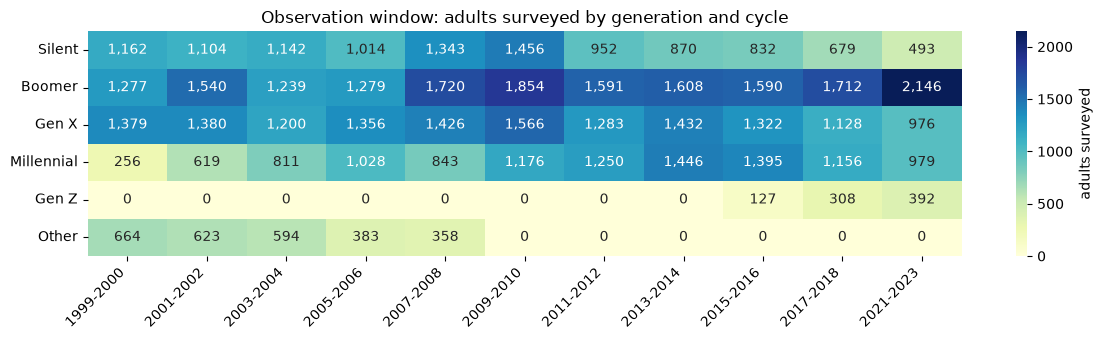

cycle,1999-2000,2001-2002,2003-2004,2005-2006,2007-2008,2009-2010,2011-2012,2013-2014,2015-2016,2017-2018,2021-2023
generation,,,,,,,,,,,
Silent,1162,1104,1142,1014,1343,1456,952,870,832,679,493
Boomer,1277,1540,1239,1279,1720,1854,1591,1608,1590,1712,2146
Gen X,1379,1380,1200,1356,1426,1566,1283,1432,1322,1128,976
Millennial,256,619,811,1028,843,1176,1250,1446,1395,1156,979
Gen Z,0,0,0,0,0,0,0,0,127,308,392
Other,664,623,594,383,358,0,0,0,0,0,0


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

GEN_ORDER = ["Silent", "Boomer", "Gen X", "Millennial", "Gen Z", "Other"]

counts = pd.crosstab(pooled["generation"], pooled["cycle"])
counts = counts.reindex([g for g in GEN_ORDER if g in counts.index])

fig, ax = plt.subplots(figsize=(12, 3.5))
sns.heatmap(counts, annot=True, fmt=",d", cmap="YlGnBu",
            cbar_kws={"label": "adults surveyed"}, ax=ax)
ax.set_title("Observation window: adults surveyed by generation and cycle")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

counts

## Chart A: 
## Grouped bars. Ten-year bands here, since 5-year bands would mean 60 bars.

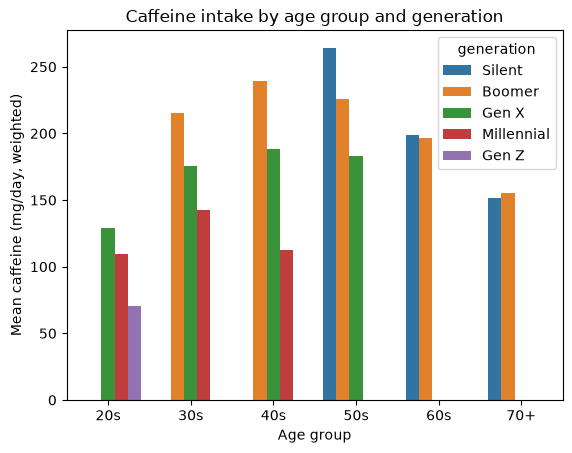

In [10]:
g10 = pooled.query("generation != 'Other' and age >= 20").assign(
    age_band=lambda d: pd.cut(d.age, [20, 30, 40, 50, 60, 70, 81], right=False,
                              labels=["20s", "30s", "40s", "50s", "60s", "70+"]),
    wx=lambda d: d.caffeine_mg * d.diet_weight,
)

bars = (g10.groupby(["age_band", "generation"], as_index=False, observed=True)
           .agg(wx=("wx", "sum"), w=("diet_weight", "sum"), n=("caffeine_mg", "size"))
           .query("n >= 50")
           .assign(mean_caffeine=lambda d: d.wx / d.w))

ax = sns.barplot(data=bars, x="age_band", y="mean_caffeine", hue="generation",
                 hue_order=[x for x in GEN_ORDER if x in set(bars.generation)])
ax.set(title="Caffeine intake by age group and generation",
       xlabel="Age group", ylabel="Mean caffeine (mg/day, weighted)");

### What this shows

- Within every age group, the younger the generation, the shorter the bar.
- Bars rise across age groups for all cohorts: intake builds with age.
- Gaps are largest in the 30s and 40s, the peak consumption years, so the
  generational difference matters most where the volume is.

## Chart B: 
## Birth-year scatter. Holds age constant at 30-39 so only birth year varies.

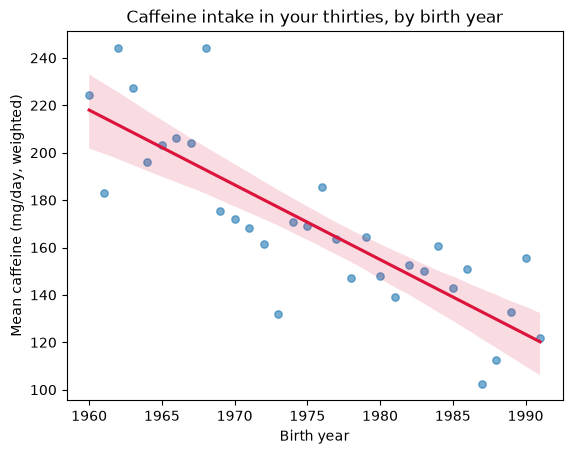

In [12]:
cohort = (pooled.query("30 <= age <= 39")
                .assign(wx=lambda d: d.caffeine_mg * d.diet_weight)
                .groupby("birth_year", as_index=False)
                .agg(wx=("wx", "sum"), w=("diet_weight", "sum"), n=("caffeine_mg", "size"))
                .query("n >= 30")
                .assign(mean_caffeine=lambda d: d.wx / d.w))

ax = sns.regplot(data=cohort, x="birth_year", y="mean_caffeine",
                 scatter_kws={"s": 28, "alpha": 0.6}, line_kws={"color": "crimson"})
ax.set(title="Caffeine intake in your thirties, by birth year",
       xlabel="Birth year", ylabel="Mean caffeine (mg/day, weighted)");

### What this shows

- Every dot is one birth year, measured at the same life stage (ages 30-39),
  so age is held constant and only the cohort changes.
- The downward slope is the cohort effect on its own, with no age or
  period confounding.
- This is the chart the forecast extends: the slope is the trend we project
  forward to 2035.

In [13]:
from scipy import stats

fit = stats.linregress(cohort.birth_year, cohort.mean_caffeine)
print(f"slope: {fit.slope:.2f} mg per birth year")
print(f"R²:    {fit.rvalue**2:.2f}")
print(f"fitted on birth years {cohort.birth_year.min():.0f}-{cohort.birth_year.max():.0f}")

for by in [1996, 2000, 2005]:
    print(f"born {by}: {fit.intercept + fit.slope * by:.0f} mg/day predicted in their thirties")

slope: -3.15 mg per birth year
R²:    0.69
fitted on birth years 1960-1991
born 1996: 104 mg/day predicted in their thirties
born 2000: 92 mg/day predicted in their thirties
born 2005: 76 mg/day predicted in their thirties


In [14]:
for lo, hi in [(20, 29), (30, 39), (40, 49), (50, 59)]:
    c = (pooled.query("@lo <= age <= @hi")
               .assign(wx=lambda d: d.caffeine_mg * d.diet_weight)
               .groupby("birth_year", as_index=False)
               .agg(wx=("wx", "sum"), w=("diet_weight", "sum"), n=("caffeine_mg", "size"))
               .query("n >= 30")
               .assign(mean_caffeine=lambda d: d.wx / d.w))
    f = stats.linregress(c.birth_year, c.mean_caffeine)
    print(f"ages {lo}-{hi}: slope {f.slope:+.2f} mg/birth-year, R² {f.rvalue**2:.2f}, "
          f"births {c.birth_year.min():.0f}-{c.birth_year.max():.0f}, {len(c)} cohorts")

ages 20-29: slope -3.15 mg/birth-year, R² 0.70, births 1970-2000, 31 cohorts
ages 30-39: slope -3.15 mg/birth-year, R² 0.69, births 1960-1991, 32 cohorts
ages 40-49: slope -5.56 mg/birth-year, R² 0.46, births 1950-1981, 32 cohorts
ages 50-59: slope -3.84 mg/birth-year, R² 0.55, births 1940-1971, 32 cohorts


### Robustness check: does the trend hold at every age?

Ran the same birth-year regression separately for people in their 20s, 30s,
40s and 50s. If the decline only showed up in one age group, it would be a
quirk of that slice rather than a real generational shift.

- **All four slopes are negative.** Later birth years drink less caffeine at
  every life stage, so the effect is genuine rather than an artifact of
  which age group we looked at.
- **Around 3 mg lost per birth year.** The 20s and 30s agree exactly at
  -3.15 and have the strongest fits. The 40s figure (-5.56) is steeper but
  much noisier, so we treat it as an upper bound, not the headline.
- **The 20s group includes births up to 2000**, meaning early Gen Z shows
  the same decline as everyone before them. The trend continues into the
  youngest cohorts we can observe, which is what makes projecting it forward
  defensible.

In [15]:
from sklearn.linear_model import LinearRegression

X = cohort[["birth_year"]]
y = cohort["mean_caffeine"]
w = cohort["w"]                     # total survey weight behind each birth year

m = LinearRegression().fit(X, y, sample_weight=w)

print(f"unweighted slope: {fit.slope:+.2f} mg per birth year")
print(f"weighted slope:   {m.coef_[0]:+.2f} mg per birth year")
print(f"weighted R²:      {m.score(X, y, sample_weight=w):.2f}")

unweighted slope: -3.15 mg per birth year
weighted slope:   -3.25 mg per birth year
weighted R²:      0.62


### Weighted result

Refitting with each birth year's total survey weight moves the slope from
-3.15 to **-3.25 mg per birth year** (R² 0.62). The two agree closely, so the
decline is not an artifact of small cohorts having outsized influence.

Headline figure for the project: **each later birth year consumes about
3.25 mg/day less caffeine than the one before, measured at the same age.**
Across the 36 birth years observed, that compounds to roughly a halving of
per-capita intake.

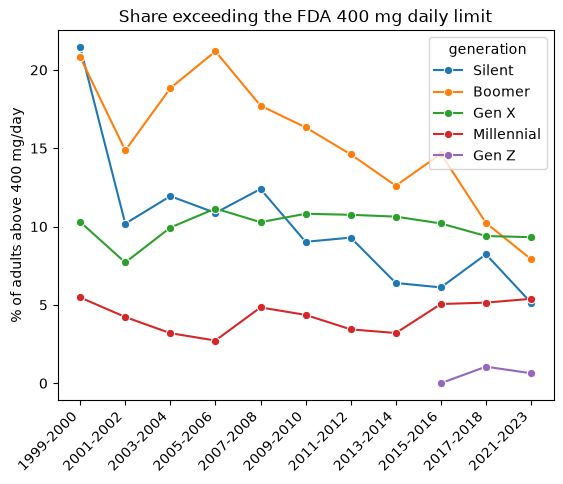

In [16]:
risk = (pooled.query("generation != 'Other'")
              .assign(over=lambda d: (d.caffeine_mg > 400) * d.diet_weight)
              .groupby(["cycle", "generation"], as_index=False)
              .agg(over=("over", "sum"), w=("diet_weight", "sum"), n=("caffeine_mg", "size"))
              .query("n >= 50")
              .assign(pct_over_400=lambda d: 100 * d.over / d.w))

ax = sns.lineplot(data=risk, x="cycle", y="pct_over_400", hue="generation",
                  hue_order=[x for x in GEN_ORDER if x in set(risk.generation)], marker="o")
ax.set(title="Share exceeding the FDA 400 mg daily limit",
       xlabel="", ylabel="% of adults above 400 mg/day")
plt.xticks(rotation=45, ha="right");

### Heavy users: share above the FDA 400 mg limit

- Each generation's peak is roughly half the previous one: Boomers 21%,
  Gen X 10%, Millennials 5%, Gen Z under 1%.
- The Boomer decline over time is an ageing effect, not a behaviour change.
  Gen X has held flat near 10% for two decades.
- Millennials show no sign of rising toward Gen X levels as they age, so the
  heavy-user segment is not being replenished.

Note: Silent generation figures before 2005 are volatile due to small cell
sizes and should not be read closely.

In [17]:
CLEAN = Path("../data/clean")
CLEAN.mkdir(parents=True, exist_ok=True)

exports = {
    "pooled_adults":            pooled.drop(columns=["age_band"], errors="ignore"),
    "intake_by_age_generation": curve[["generation", "age_band", "mean_caffeine", "n"]],
    "intake_by_age_group":      bars[["age_band", "generation", "mean_caffeine", "n"]],
    "intake_by_birth_year":     cohort[["birth_year", "mean_caffeine", "n"]],
    "share_over_400mg":         risk[["cycle", "generation", "pct_over_400", "n"]],
}

for name, df in exports.items():
    path = CLEAN / f"{name}.csv"
    df.to_csv(path, index=False)
    print(f"{name:26} {len(df):>7,} rows  ->  {path.name}")

pooled_adults               57,459 rows  ->  pooled_adults.csv
intake_by_age_generation        33 rows  ->  intake_by_age_generation.csv
intake_by_age_group             16 rows  ->  intake_by_age_group.csv
intake_by_birth_year            32 rows  ->  intake_by_birth_year.csv
share_over_400mg                47 rows  ->  share_over_400mg.csv
